<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 2: Linear Regression

*Simple and multiple linear regression with statsmodels and ISLP: estimation, inference, prediction, diagnostics, interactions, non-linear terms and qualitative predictors*

**Chapter:** ISLP Chapter 3 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [49]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Nguyễn Anh Tú"
STUDENT_ID   = "ITDSIU23026"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 2 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 2 | Nguyễn Anh Tú | ITDSIU23026 | IT171IU – Lab Group 01


In [50]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.14.7


In [51]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

<span style="color:red">For every exercise write **code + output + a short interpretation**. Exercises 1–7 are compulsory; 8–9 are challenge (bonus) exercises. Use `load_data()` for the ISLP data sets and `load_extra()` (defined in the Setup section) for the additional data sets.</span>

## <span style="color:red">Exercise 1 – Simple regression on `Auto`</span>

- <span style="color:red">**(a)** Fit `mpg` on `horsepower` with `sm.OLS` and print the summary.</span>
- <span style="color:red">**(b)** Is there a relationship between the predictor and the response? How strong is it ($R^2$, RSE)? Is it positive or negative?</span>
- <span style="color:red">**(c)** What is the predicted `mpg` for `horsepower = 98`? Give the 95% **confidence** and **prediction** intervals.</span>
- <span style="color:red">**(d)** Plot `mpg` against `horsepower` with the least-squares line (use the `abline()` function of the lab) and draw the residual plot. Comment on any problems.</span>

In [ ]:
from ISLP import load_data
from ISLP.models import ModelSpec as MS, summarize
import statsmodels.api as sm
import pandas as pd
import numpy as np
# a
Auto = load_data('Auto')
design_hp = MS(['horsepower'])
X_hp = design_hp.fit_transform(Auto)
fit_hp = sm.OLS(Auto['mpg'], X_hp).fit()
summarize(fit_hp)
print(fit_hp.summary())


                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           7.03e-81
Time:                        13:21:19   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     39.9359      0.717     55.660      0.0

b/ Look at the P>|t| column for horsepower. It is approximately 0. Reject H0. There is definitely a relationship.
Check fit_hp.rsquared (around 0.606). This means horsepower explains ~60.6% of the variance in fuel consumption.
The coef of horsepower is negative (around -0.1578).  Negative relationship (the higher the horsepower, the worse the fuel economy).

In [53]:
# c
new = pd.DataFrame({'horsepower': [98]})
newX = design_hp.transform(new)
new_predictions = fit_hp.get_prediction(newX)
print("Predicted mpg:", new_predictions.predicted_mean[0])
print("95% Confidence Interval:", new_predictions.conf_int(alpha=0.05))
print("95% Prediction Interval:", new_predictions.conf_int(obs=True, alpha=0.05))

Predicted mpg: 24.467077152512427
95% Confidence Interval: [[23.97307896 24.96107534]]
95% Prediction Interval: [[14.80939607 34.12475823]]


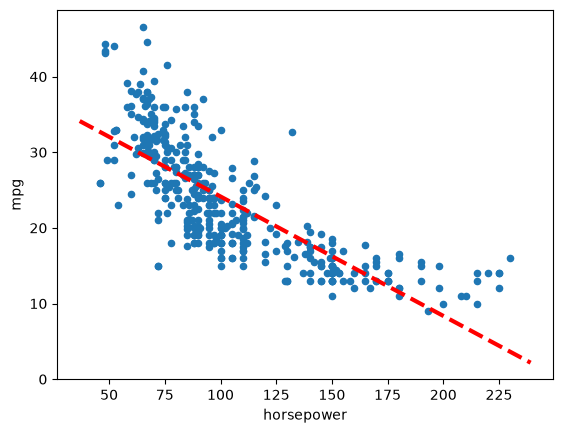

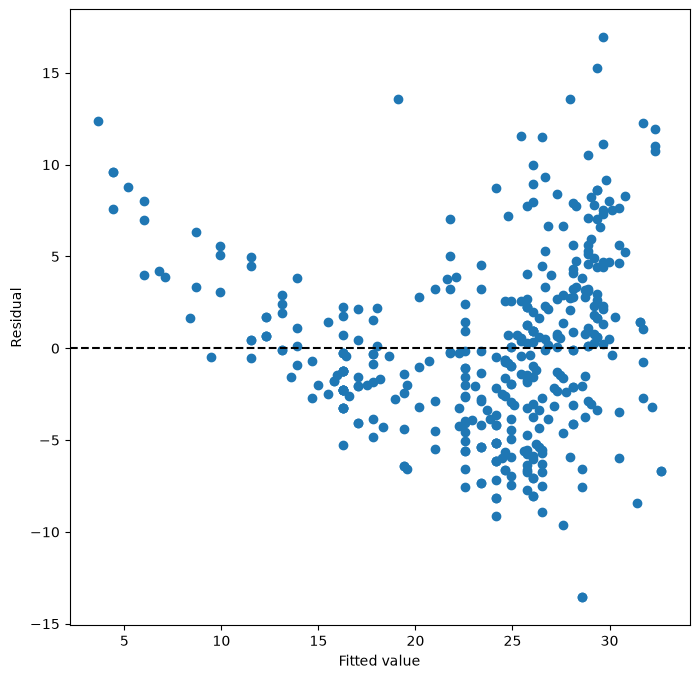

In [54]:
# d
from matplotlib.pyplot import subplots
def abline(ax, b, m, *args, **kwargs):
    "Add a line with slope m and intercept b to ax"
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim, *args, **kwargs)
ax = Auto.plot.scatter('horsepower', 'mpg')
abline(ax,
       fit_hp.params['intercept'],
       fit_hp.params['horsepower'],
       'r--',
       linewidth=3)
ax = subplots(figsize=(8, 8))[1]
ax.scatter(fit_hp.fittedvalues, fit_hp.resid)
ax.set_xlabel("Fitted value")
ax.set_ylabel("Residual")
ax.axhline(0, c="k", ls="--")


The residual plot displays a clear U-shaped pattern. This violates a fundamental assumption of Linear Regression: errors (residuals) must be randomly distributed. The relationship between mpg and horsepower is not linear. A non-linear model (such as polynomial regression or logarithmic transformation) is required for subsequent exercises.

## <span style="color:red">Exercise 2 – Multiple regression on `Auto`</span>

- <span style="color:red">**(a)** Produce the correlation matrix of the quantitative variables (exclude `name`).</span>
- <span style="color:red">**(b)** Fit `mpg` on **all** other variables except `name`. Which predictors are significant? What does the coefficient of `year` suggest?</span>
- <span style="color:red">**(c)** Draw the residual plot and the leverage plot. Are there unusually large outliers or high-leverage points?</span>
- <span style="color:red">**(d)** Compute the VIF of each predictor. Which ones indicate collinearity?</span>

In [55]:
# a
Auto_num = Auto.drop(columns=['name']) if 'name' in Auto.columns else Auto.copy()
print(Auto_num.corr().round(2))

               mpg  cylinders  displacement  horsepower  weight  acceleration  \
mpg           1.00      -0.78         -0.81       -0.78   -0.83          0.42   
cylinders    -0.78       1.00          0.95        0.84    0.90         -0.50   
displacement -0.81       0.95          1.00        0.90    0.93         -0.54   
horsepower   -0.78       0.84          0.90        1.00    0.86         -0.69   
weight       -0.83       0.90          0.93        0.86    1.00         -0.42   
acceleration  0.42      -0.50         -0.54       -0.69   -0.42          1.00   
year          0.58      -0.35         -0.37       -0.42   -0.31          0.29   
origin        0.57      -0.57         -0.61       -0.46   -0.59          0.21   

              year  origin  
mpg           0.58    0.57  
cylinders    -0.35   -0.57  
displacement -0.37   -0.61  
horsepower   -0.42   -0.46  
weight       -0.31   -0.59  
acceleration  0.29    0.21  
year          1.00    0.18  
origin        0.18    1.00  


In [56]:
# b
terms = Auto_num.columns.drop('mpg')
X_all = MS(terms).fit_transform(Auto_num)
fit_all = sm.OLS(Auto['mpg'], X_all).fit()
summarize(fit_all)                

,coef,std err,t,P>|t|
intercept,-17.2184,4.644,-3.707,0.000
cylinders,-0.4934,0.323,-1.526,0.128
displacement,0.0199,0.008,2.647,0.008
horsepower,-0.0170,0.014,-1.230,0.220
weight,-0.0065,0.001,-9.929,0.000
acceleration,0.0806,0.099,0.815,0.415
year,0.7508,0.051,14.729,0.000
origin,1.4261,0.278,5.127,0.000


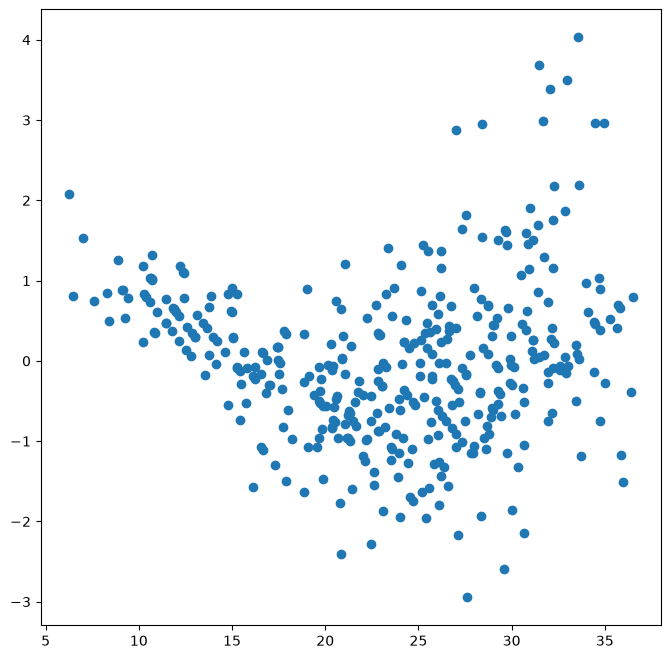

In [57]:
# c
infl = fit_all.get_influence()
stud = infl.resid_studentized_external
lev = infl.hat_matrix_diag

ax = subplots(figsize=(8, 8))[1]
ax.scatter(fit_all.fittedvalues, stud)

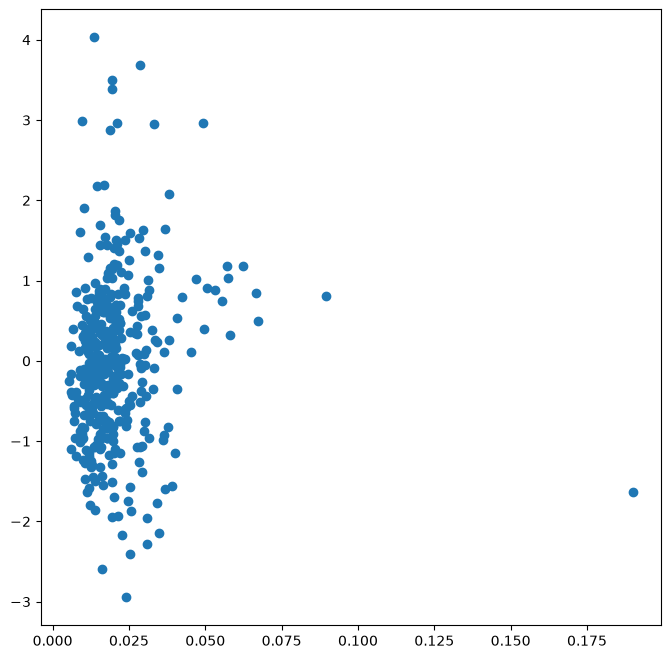

In [58]:
ax = subplots(figsize=(8, 8))[1]
ax.scatter(lev, stud)

In [59]:
# d
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

vals = [VIF(X_all.values, i)
         for i in range(1, X_all.shape[1])]
vif = pd.DataFrame({'vif': vals}, 
                      index=X_all.columns[1:])
print(vif)

                    vif
cylinders     10.737535
displacement  21.836792
horsepower     9.943693
weight        10.831260
acceleration   2.625806
year           1.244952
origin         1.772386


## <span style="color:red">Exercise 3 – Interactions and transformations</span>

<span style="color:red">Starting from Exercise 2, try **at least three** of the following and report $R^2$, the significance of the new terms and an `anova_lm()` comparison with the model without them:</span>

- <span style="color:red">an interaction such as `('horsepower', 'weight')` or `('displacement', 'year')`;</span>
- <span style="color:red">`poly('horsepower', degree=2)`;</span>
- <span style="color:red">$\log(\text{horsepower})$, $\sqrt{\text{horsepower}}$ or $\text{horsepower}^2$ (create new columns first).</span>

<span style="color:red">Which model would you choose and why?</span>

In [60]:
import numpy as np
import statsmodels.api as sm
from ISLP.models import ModelSpec as MS, summarize, poly
from statsmodels.stats.anova import anova_lm

Auto_num['log_hp'] = np.log(Auto_num['horsepower'])
base = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'horsepower']).fit_transform(Auto_num)).fit()
inter = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'horsepower', ('horsepower', 'weight')]).fit_transform(Auto_num)).fit()
print(anova_lm(base, inter))

   df_resid          ssr  df_diff      ss_diff           F        Pr(>F)
0     388.0  4565.650523      0.0          NaN         NaN           NaN
1     387.0  3397.738458      1.0  1167.912065  133.024356  1.180727e-26


In [61]:
poly = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', poly('horsepower', degree=2)]).fit_transform(Auto_num)).fit()
print(anova_lm(base, poly))

   df_resid          ssr  df_diff     ss_diff          F        Pr(>F)
0     388.0  4565.650523      0.0         NaN        NaN           NaN
1     387.0  3737.322742      1.0  828.327781  85.773393  1.413402e-18


In [62]:
log = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'log_hp']).fit_transform(Auto_num)).fit()
print(f"Base R^2: {base.rsquared:.4f} | Log R^2: {log.rsquared:.4f}")
print(summarize(log).loc[['log_hp']])

Base R^2: 0.8083 | Log R^2: 0.8168
          coef  std err      t  P>|t|
log_hp -4.5615    1.067 -4.274    0.0


## <span style="color:red">Exercise 4 – Qualitative predictors with `Carseats`</span>

- <span style="color:red">**(a)** Fit `Sales` on `Price`, `Urban` and `US`.</span>
- <span style="color:red">**(b)** Interpret each coefficient – careful, `Urban` and `US` are qualitative.</span>
- <span style="color:red">**(c)** Write the model in equation form, with the dummy variables written out.</span>
- <span style="color:red">**(d)** For which predictors can you reject $H_0: \beta_j = 0$? Fit a smaller model with only those predictors and compare the two fits ($R^2$, RSE, `anova_lm`).</span>
- <span style="color:red">**(e)** Give 95% confidence intervals for the coefficients of the smaller model (`conf_int()`).</span>

In [63]:
# a
from ISLP import load_data
from ISLP.models import ModelSpec as MS, summarize
import statsmodels.api as sm

Carseats = load_data('Carseats')
X_c = MS(['Price', 'Urban', 'US']).fit_transform(Carseats)
Y_c = Carseats['Sales']
fit_c = sm.OLS(Y_c, X_c).fit()
summarize(fit_c)                    


,coef,std err,t,P>|t|
intercept,13.0435,0.651,20.036,0.000
Price,-0.0545,0.005,-10.389,0.000
Urban[Yes],-0.0219,0.272,-0.081,0.936
US[Yes],1.2006,0.259,4.635,0.000


b/ Holding all other predictors fixed, stores located in the US sell on average 1,200 more units than non-US stores.
c/ Sales = 13.04 - 0.054 * Price + 0.02 * Urban[Yes] + 1.20 * US[Yes]

In [64]:
# d
from statsmodels.stats.anova import anova_lm

X_c_small = MS(['Price', 'US']).fit_transform(Carseats)
fit_c_small = sm.OLS(Y_c, X_c_small).fit()
print(anova_lm(fit_c_small, fit_c))
print(f"Full Model R^2: {fit_c.rsquared:.4f} | RSE: {np.sqrt(fit_c.scale):.4f}")
print(f"Small Model R^2: {fit_c_small.rsquared:.4f} | RSE: {np.sqrt(fit_c_small.scale):.4f}")


   df_resid          ssr  df_diff  ss_diff         F    Pr(>F)
0     397.0  2420.874462      0.0      NaN       NaN       NaN
1     396.0  2420.834671      1.0  0.03979  0.006509  0.935739
Full Model R^2: 0.2393 | RSE: 2.4725
Small Model R^2: 0.2393 | RSE: 2.4694


In [65]:
# e
print(fit_c_small.conf_int(alpha=0.05))

                  0          1
intercept  11.79032  14.271265
Price      -0.06476  -0.044195
US[Yes]     0.69152   1.707766


## <span style="color:red">Exercise 5 – Simulation: what does noise do to the fit?</span>

- <span style="color:red">**(a)** Using `rng = np.random.default_rng(1)`, create $x \sim N(0,1)$ with $n = 100$ and $\varepsilon \sim N(0, 0.25)$ (variance 0.25).</span>
- <span style="color:red">**(b)** Generate $y = -1 + 0.5x + \varepsilon$. What are $\beta_0$ and $\beta_1$ of the population model?</span>
- <span style="color:red">**(c)** Fit the least-squares line, compare $\hat\beta_0, \hat\beta_1$ with the truth and draw the data with both the fitted line and the population line (different colours, legend).</span>
- <span style="color:red">**(d)** Add $x^2$ to the model. Is there evidence that the quadratic term improves the fit?</span>
- <span style="color:red">**(e)** Repeat (a)–(c) with variance 0.05 and 1.0. How do the confidence intervals of $\beta_1$ change?</span>

In [66]:
# a
import numpy as np

rng = np.random.default_rng(1)
x = rng.normal(size=100)
eps = rng.normal(scale=np.sqrt(0.25), size=100)                 

In [67]:
# b
y_sim = -1 + 0.5 * x + eps

intercept   -1.038013
X            0.484291
dtype: float64


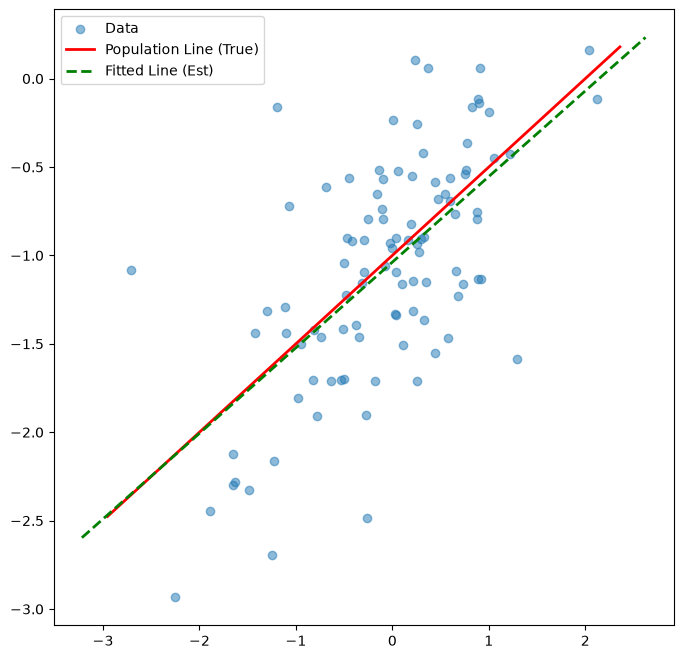

In [68]:
# c
import statsmodels.api as sm
import pandas as pd
from ISLP.models import ModelSpec as MS
from matplotlib.pyplot import subplots

df_sim = pd.DataFrame({'X': x, 'Y': y_sim})
fit_sim = sm.OLS(df_sim['Y'], MS(['X']).fit_transform(df_sim)).fit()
print(fit_sim.params)

ax = subplots(figsize=(8, 8))[1]
ax.scatter(x, y_sim, alpha=0.5, label='Data')

abline(ax, -1, 0.5, 'r', linewidth=2, label='Population Line (True)')
abline(ax,
       fit_sim.params['intercept'],
       fit_sim.params['X'],
       'g--',
       linewidth=2,
       label='Fitted Line (Est)')

ax.legend();

In [69]:
# d
from ISLP.models import poly
from statsmodels.stats.anova import anova_lm

fit_poly = sm.OLS(df_sim['Y'], MS([poly('X', degree=2)]).fit_transform(df_sim)).fit()
print(fit_poly.summary().tables[1])
print(anova_lm(fit_sim, fit_poly))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -1.0737      0.050    -21.326      0.000      -1.174      -0.974
poly(X, degree=2)[0]     4.1240      0.503      8.191      0.000       3.125       5.123
poly(X, degree=2)[1]    -0.0261      0.503     -0.052      0.959      -1.025       0.973
   df_resid        ssr  df_diff   ss_diff         F    Pr(>F)
0      98.0  24.586567      0.0       NaN       NaN       NaN
1      97.0  24.585886      1.0  0.000681  0.002688  0.958757


Variance = 0.05 (Low noise): Data points cluster tightly around the true regression line. Estimation uncertainty decreases, resulting in a significantly narrower confidence interval for B1.
Variance = 1.0 (High noise): Data points are widely scattered, obscuring the linear relationship. Estimation uncertainty increases, resulting in a much wider confidence interval for B1

## <span style="color:red">Exercise 6 – Collinearity</span>

- <span style="color:red">**(a)** Run the code in the starter cell: `y_col` depends on `x1` and `x2`, but `x2` is almost a copy of `x1`. Write the population model and its coefficients.</span>
- <span style="color:red">**(b)** What is the correlation between `x1` and `x2`? Draw a scatter plot.</span>
- <span style="color:red">**(c)** Fit `y_col` on `x1` and `x2`. Can you reject $H_0:\beta_1 = 0$? $H_0:\beta_2 = 0$? Compute the VIFs.</span>
- <span style="color:red">**(d)** Fit `y_col` on `x1` only and on `x2` only. Do the results contradict (c)? Explain.</span>

In [70]:
# a
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots

rng = np.random.default_rng(10)
x1 = rng.uniform(size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y_col = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)
D = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y_col})

In [71]:
# b
corr = np.corrcoef(D['x1'], D['x2'])[0, 1]
print(f"Correlation between x1 and x2: {corr}")

Correlation between x1 and x2: 0.772324497691354


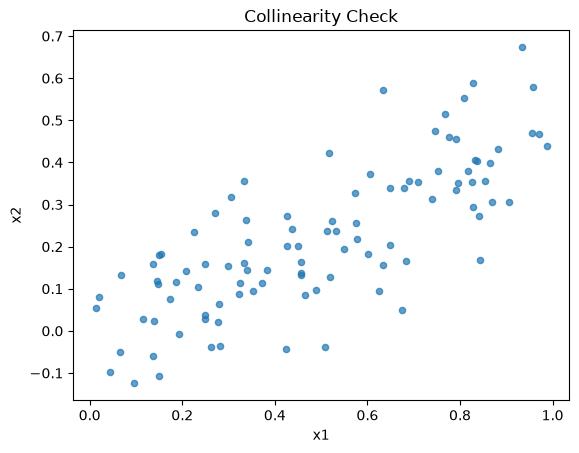

In [72]:
ax = D.plot.scatter('x1', 'x2', alpha=0.7)
ax.set_title("Collinearity Check");

In [73]:
# c
from ISLP.models import ModelSpec as MS
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

X_full = MS(['x1', 'x2']).fit_transform(D)
fit_full = sm.OLS(D['y'], X_full).fit()
print(fit_full.summary().tables[1])


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      1.9579      0.190     10.319      0.000       1.581       2.334
x1             1.6154      0.527      3.065      0.003       0.569       2.661
x2             0.9428      0.831      1.134      0.259      -0.707       2.592


In [74]:
vals = [VIF(X_full.values, i)
        for i in range(1, X_full.shape[1])]
print(vals)

[np.float64(2.478223415512032), np.float64(2.4782234155120317)]


In [75]:
# d
X_x1 = MS(['x1']).fit_transform(D)
fit_x1 = sm.OLS(D['y'], X_x1).fit()
print(fit_x1.summary().tables[1])


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      1.9371      0.189     10.242      0.000       1.562       2.312
x1             2.0771      0.335      6.196      0.000       1.412       2.742


In [76]:
X_x2 = MS(['x2']).fit_transform(D)
fit_x2 = sm.OLS(D['y'], X_x2).fit()
print(fit_x2.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      2.3239      0.154     15.124      0.000       2.019       2.629
x2             2.9103      0.550      5.291      0.000       1.819       4.002


Because X1 and X2 are highly collinear, they carry redundant information. Once X1 is in the model, X2 adds no new explanatory power, making its marginal effect statistically insignificant.

## <span style="color:red">Exercise 7 – Additional data set: diabetes progression</span>

<span style="color:red">The file `additional-data/diabetes.csv` contains 442 diabetes patients: age, sex, body-mass index (`bmi`), blood pressure (`bp`), six blood serum measurements `s1`–`s6` and the response `progression` (a quantitative measure of disease progression one year after baseline).</span>

- <span style="color:red">**(a)** Fit `progression` on `bmi` alone, then on `bmi`, `bp` and `s5`, then on all ten predictors. Report $R^2$ and RSE for the three models.</span>
- <span style="color:red">**(b)** Use `anova_lm()` to test whether the full model is significantly better than the three-predictor model.</span>
- <span style="color:red">**(c)** Compute the VIFs in the full model. Which serum measurements are strongly collinear?</span>
- <span style="color:red">**(d)** Which three predictors would you report to a doctor as most important? Justify with the output.</span>

In [77]:
# a
import numpy as np
import pandas as pd
import statsmodels.api as sm
from ISLP.models import ModelSpec as MS, summarize
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

diabetes = load_extra('diabetes')
print(diabetes.shape); print(diabetes.head())
terms_10 = diabetes.columns.drop("progression")
y_d = diabetes['progression']
m1 = sm.OLS(y_d, MS(['bmi']).fit_transform(diabetes)).fit()
m2 = sm.OLS(y_d, MS(["bmi", "bp", "s5"]).fit_transform(diabetes)).fit()
m3 = sm.OLS(y_d, MS(terms_10).fit_transform(diabetes)).fit()

print(f"M1: R^2 = {m1.rsquared:.4f} | RSE = {np.sqrt(m1.scale):.4f}")
print(f"M2: R^2 = {m2.rsquared:.4f} | RSE = {np.sqrt(m2.scale):.4f}")
print(f"M3: R^2 = {m3.rsquared:.4f} | RSE = {np.sqrt(m3.scale):.4f}")

(442, 11)
    age  sex   bmi     bp     s1     s2    s3   s4      s5    s6  progression
0  59.0  2.0  32.1  101.0  157.0   93.2  38.0  4.0  4.8598  87.0        151.0
1  48.0  1.0  21.6   87.0  183.0  103.2  70.0  3.0  3.8918  69.0         75.0
2  72.0  2.0  30.5   93.0  156.0   93.6  41.0  4.0  4.6728  85.0        141.0
3  24.0  1.0  25.3   84.0  198.0  131.4  40.0  5.0  4.8903  89.0        206.0
4  50.0  1.0  23.0  101.0  192.0  125.4  52.0  4.0  4.2905  80.0        135.0
M1: R^2 = 0.3439 | RSE = 62.5151
M2: R^2 = 0.4801 | RSE = 55.7782
M3: R^2 = 0.5177 | RSE = 54.1542


In [78]:
# b
print(anova_lm(m2, m3))

   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     438.0  1.362709e+06      0.0           NaN       NaN       NaN
1     431.0  1.263986e+06      7.0  98722.908072  4.809002  0.000031


With Pr(>F) < 0.05, we reject H0. The 7 additional predictors provide significant explanatory power, confirming that the full 10-predictor model is superior

In [79]:
# c
vals = [VIF(X3.values, i) 
        for i in range(1, MS(terms_10).fit_transform(diabetes).shape[1])]
vif = pd.DataFrame({'VIF': vals}, index=X3.columns[1:])
print(vif)

           VIF
age   1.217307
sex   1.278071
bmi   1.509437
bp    1.459428
s1   59.202510
s2   39.193370
s3   15.402156
s4    8.890986
s5   10.075967
s6    1.484623


High VIF values for s1 and s2 (~50–60) confirm severe collinearity. These two serum measurements carry heavily overlapping information, introducing noise and variance into the OLS model.

In [80]:
# d
summarize(m3)

,coef,std err,t,P>|t|
intercept,-334.5671,67.455,-4.960,0.000
age,-0.0364,0.217,-0.168,0.867
sex,-22.8596,5.836,-3.917,0.000
bmi,5.6030,0.717,7.813,0.000
bp,1.1168,0.225,4.958,0.000
s1,-1.0900,0.573,-1.901,0.058
s2,0.7465,0.531,1.406,0.160
s3,0.3720,0.782,0.475,0.635
s4,6.5338,5.959,1.097,0.273
s5,68.4831,15.670,4.370,0.000


With the lowest p-values (p<0.001), bmi, bp, and s5 are the most statistically significant predictors of disease progression. Clinicians should prioritize tracking these three metrics—which also align perfectly with the specification of Model m2.

## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 8 – Your own `ols()` function</span>

<span style="color:red">Write a function `ols(X, y)` that uses only NumPy to return a data frame with the coefficient, standard error, $t$-statistic and two-sided $p$-value of each column of `X` (use `scipy.stats.t.sf`), plus $R^2$ and the $F$-statistic. Check it against `sm.OLS` on the Boston model with all predictors.</span>

In [81]:
import numpy as np
import pandas as pd
from scipy import stats

def ols(X, y):
    Xn, yn = np.asarray(X, float), np.asarray(y, float)
    n, p1 = Xn.shape
    p = p1 - 1
    
    beta_hat = np.linalg.solve(Xn.T @ Xn, Xn.T @ yn)
    resid = yn - Xn @ beta_hat
    sigma2 = (resid @ resid) / (n - p1)
    se = np.sqrt(sigma2 * np.diag(np.linalg.inv(Xn.T @ Xn)))
    
    t_stat = beta_hat / se
    p_values = 2 * stats.t.sf(np.abs(t_stat), df=n - p1)
    
    TSS = np.sum((yn - yn.mean())**2)
    RSS = resid @ resid
    R2 = 1 - RSS / TSS
    F_stat = ((TSS - RSS) / p) / (RSS / (n - p1))
    
    cols = X.columns if hasattr(X, 'columns') else [f'X{i}' for i in range(p1)]
    result_df = pd.DataFrame({
        'coef': beta_hat,
        'std err': se,
        't': t_stat,
        'P>|t|': p_values
    }, index=cols)
    
    return result_df, R2, F_stat

In [82]:
from ISLP import load_data
from ISLP.models import ModelSpec as MS

Boston = load_data('Boston')
terms_all = Boston.columns.drop('medv')
X_all = MS(terms_all).fit_transform(Boston)
y_all = Boston['medv']

df_custom, r2_custom, f_custom = ols(X_all, y_all)
print(f"R^2 = {r2_custom:.4f} | F-statistic = {f_custom:.4f}")
df_custom.round(4)

R^2 = 0.7343 | F-statistic = 113.5438


,coef,std err,t,P>|t|
intercept,41.6173,4.9360,8.4313,0.0000
crim,-0.1214,0.0330,-3.6784,0.0003
zn,0.0470,0.0139,3.3838,0.0008
indus,0.0135,0.0621,0.2167,0.8285
chas,2.8400,0.8700,3.2643,0.0012
nox,-18.7580,3.8514,-4.8705,0.0000
rm,3.6581,0.4202,8.7047,0.0000
age,0.0036,0.0133,0.2709,0.7866
dis,-1.4908,0.2016,-7.3938,0.0000
rad,0.2894,0.0669,4.3254,0.0000


In [83]:
import statsmodels.api as sm
from ISLP.models import summarize

fit_sm = sm.OLS(y_all, X_all).fit()
print(f"R^2 = {fit_sm.rsquared:.4f} | F-statistic = {fit_sm.fvalue:.4f}")
summarize(fit_sm)

R^2 = 0.7343 | F-statistic = 113.5438


,coef,std err,t,P>|t|
intercept,41.6173,4.936,8.431,0.000
crim,-0.1214,0.033,-3.678,0.000
zn,0.0470,0.014,3.384,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8400,0.870,3.264,0.001
nox,-18.7580,3.851,-4.870,0.000
rm,3.6581,0.420,8.705,0.000
age,0.0036,0.013,0.271,0.787
dis,-1.4908,0.202,-7.394,0.000
rad,0.2894,0.067,4.325,0.000
